# Chapter 1: Common Conventions and API Elements of scikit-learn

This notebook covers Chapter 1 of *scikit-learn Cookbook* (3rd Edition, Packt). The chapter is mostly conceptual: it introduces the design principles of scikit-learn and the common API that every component in the library follows. The code below consists of small, self-contained examples that illustrate each concept.

**Topics covered:**
- The design philosophy behind scikit-learn
- Estimators: `fit()`, `predict()`, and `fit_predict()`
- Transformers: `fit()`, `transform()`, and `fit_transform()`
- Building custom transformers and estimators
- Pipelines and saving a full workflow
- Common attributes (`coef_`, `intercept_`) and evaluation with `score()`
- Hyperparameters: `get_params()`, `set_params()`, `GridSearchCV()`, and `RandomizedSearchCV()`
- Metadata: estimator tags and metadata routing
- Best practices for using the API

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

import sklearn
from sklearn.datasets import make_blobs, load_breast_cancer, load_diabetes
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.utils import get_tags
from scipy.stats import loguniform

print(f'scikit-learn version: {sklearn.__version__}')
print(f'NumPy version: {np.__version__}')
print(f'pandas version: {pd.__version__}')

scikit-learn version: 1.9.1
NumPy version: 2.5.3
pandas version: 3.0.6


The versions above are the ones used to run this notebook. All examples use the public scikit-learn API, so they should work on any recent version (1.6 or newer, which introduced the `get_tags()` function used in Section 8).

## 1. scikit-learn's Design Philosophy

scikit-learn started in 2007 and was officially released in 2009. Its popularity does not come from a single algorithm, but from a **consistent and modular design** that makes every algorithm feel familiar. The design rests on a few principles:

1. **Consistency**: all objects share a small common interface (`fit()`, `predict()`, `transform()`). Learning one model means you already know how to use the others.
2. **Simplicity**: every hyperparameter has a sensible default, so a working model can be built in a few lines and tuned later.
3. **Modularity**: preprocessing steps, models, and evaluation tools are independent building blocks that can be combined freely.
4. **Reusability**: components written for one project, including custom ones, can be plugged into another project's workflow without changes.
5. **Inspection**: hyperparameters and learned values are stored as public attributes, so the model can always be examined.

A practical consequence of this design is that **switching algorithms is cheap**: replacing a logistic regression with a random forest usually means changing a single line of code.

Data follows a standard convention: the feature matrix is called $\mathbf{X}$ with shape $n \times p$ ($n$ samples, $p$ features), and the target vector is called $\mathbf{y}$ with length $n$. Both can be NumPy arrays, pandas objects, or SciPy sparse matrices.

**On the name:** the library is always written in lowercase, **scikit-learn**. The "sci" comes from *SciPy*, and the name can be read as a *science kit for learning*.

## 2. Understanding Estimators

An **estimator** is any object that learns from data. It is the central abstraction of scikit-learn: classifiers, regressors, clustering algorithms, and preprocessing tools are all estimators, and all of them implement `fit()`.

Every estimator follows the same three steps:
1. **Create** it and set its hyperparameters in the constructor: `model = Estimator(...)`
2. **Fit** it to data: `model.fit(X, y)` (or `model.fit(X)` for unsupervised methods)
3. **Use** it: `model.predict(X_new)`, `model.transform(X_new)`, or inspect what it learned

For supervised learning, fitting means learning a function

$$\hat{f}: \mathbf{X} \rightarrow \mathbf{y}$$

that maps features to targets, and `predict()` applies $\hat{f}$ to new data.

### 2.1 Linear Regression: A Simple Supervised Estimator

Linear regression looks for weights $\mathbf{w}$ and a bias $b$ that minimize the sum of squared residuals:

$$\min_{\mathbf{w}, b} \sum_{i=1}^{n} \left( y_i - (\mathbf{w}^T \mathbf{x}_i + b) \right)^2$$

The example below uses a small made-up dataset: the number of hours a student studied and the exam score they received.

In [2]:
# Hours studied (feature) and exam score (target)
X_hours = np.array([[1], [2], [3], [4], [5], [6]])
y_score = np.array([52, 55, 61, 64, 70, 73])

# 1. Create  2. Fit  3. Predict
reg = LinearRegression()
reg.fit(X_hours, y_score)

X_new = np.array([[7], [8]])
print('Predicted scores for 7 and 8 hours:', reg.predict(X_new).round(2))

Predicted scores for 7 and 8 hours: [77.8  82.17]


The model learned a positive linear trend: each extra hour of study is associated with a higher exam score, so the predicted scores for 7 and 8 hours continue that trend. The same three lines (`LinearRegression()`, `fit()`, `predict()`) would work unchanged for almost any other supervised model in scikit-learn.

### 2.2 `fit_predict()`: A Shortcut for Unsupervised Learning

Some estimators provide `fit_predict()`, which fits the model and returns labels for the same data in one call. It is mainly used in **unsupervised learning**, where there is no target $\mathbf{y}$ and the goal is to find structure in the training data itself.

**K-Means** clustering divides the data into $K$ groups by minimizing the within-cluster sum of squared distances to each cluster's center (centroid):

$$\min_{C_1, \ldots, C_K} \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \boldsymbol{\mu}_k\|^2$$

where $\boldsymbol{\mu}_k$ is the mean of the points in cluster $C_k$. Below, K-Means is applied to synthetic 2D data generated with three natural groups.

First 10 cluster labels: [1 0 1 0 2 0 1 2 0 1]
Cluster centers:
 [[-8.41  5.51]
 [ 9.59  0.77]
 [-1.42  4.51]]


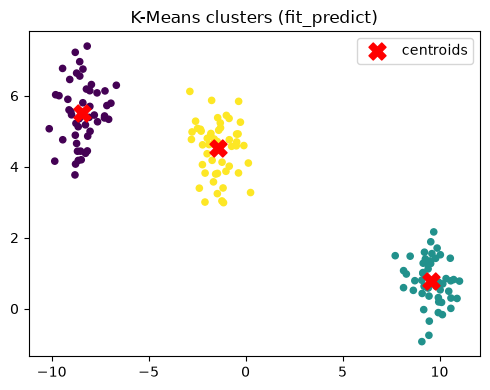

In [3]:
X_blobs, _ = make_blobs(n_samples=150, centers=3, cluster_std=0.8, random_state=7)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=7)
labels = kmeans.fit_predict(X_blobs)

print('First 10 cluster labels:', labels[:10])
print('Cluster centers:\n', kmeans.cluster_centers_.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap='viridis', s=20)
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
           c='red', marker='X', s=150, label='centroids')
ax.set_title('K-Means clusters (fit_predict)')
ax.legend()
plt.tight_layout()
plt.show()

K-Means found the three groups and placed a centroid (red X) in the middle of each one. The labels (0, 1, 2) are arbitrary names for the clusters: they carry no meaning by themselves.

**When to use which:**
- **Supervised learning**: call `fit(X_train, y_train)` and then `predict(X_test)` separately, keeping training and test data apart.
- **Unsupervised learning**: `fit_predict(X)` is convenient when the labels for the training data itself are what you need. Separate `fit()` and `predict()` are still useful when new points must be assigned to existing clusters later.

## 3. Transformers and the `transform()` Method

A **transformer** is an estimator that changes the data instead of predicting a target. Transformers share the `fit()` interface but add:
- `fit(X)`: learn the parameters needed for the transformation from the data
- `transform(X)`: apply the learned transformation
- `fit_transform(X)`: both steps in one call

### 3.1 StandardScaler: z-Score Standardization

The most common transformation is **standardization**, which gives each feature a mean of 0 and a standard deviation of 1:

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

where $\mu_j$ and $\sigma_j$ are the mean and standard deviation of feature $j$, learned during `fit()`.

**Why standardize?** Algorithms that rely on distances or gradients (k-nearest neighbors, SVMs, logistic regression, neural networks) are sensitive to feature scale. Without scaling, a feature measured in large units would dominate one measured in small units.

The example uses the height (cm) and weight (kg) of three people, two features on different scales.

In [4]:
X_body = np.array([[160, 55],
                   [170, 65],
                   [180, 80]])

scaler = StandardScaler()
scaler.fit(X_body)                 # learn mean and std
X_body_scaled = scaler.transform(X_body)

print('Learned mean (mean_):', scaler.mean_)
print('Learned std (scale_):', scaler.scale_.round(4))
print('\nScaled data:\n', X_body_scaled.round(4))

# Manual check for the first person's height
z_manual = (160 - scaler.mean_[0]) / scaler.scale_[0]
print(f'\nManual z-score for height 160: {z_manual:.4f}')

Learned mean (mean_): [170.          66.66666667]
Learned std (scale_): [ 8.165 10.274]

Scaled data:
 [[-1.2247 -1.1355]
 [ 0.     -0.1622]
 [ 1.2247  1.2978]]

Manual z-score for height 160: -1.2247


The scaler learned a mean height of 170 cm and a mean weight of about 66.7 kg. After scaling, both columns are centered at 0 and expressed in "number of standard deviations from the mean", so height and weight are now on comparable scales. The manual calculation for the first person matches the scaled value exactly.

### 3.2 `fit_transform()` and the Train/Test Rule

`fit_transform()` is the standard way to scale training data. The key rule is:

- **Training data**: `fit_transform()` (learn the parameters and apply them)
- **Test data**: `transform()` only (reuse the parameters learned from training)

Fitting the scaler again on the test data would compute a different mean and standard deviation, which leaks information from the test set and puts training and test data on different scales. This mistake is called **data leakage**.

In [5]:
rng = np.random.default_rng(0)
X_demo = rng.normal(loc=50, scale=10, size=(100, 2))
X_tr, X_te = train_test_split(X_demo, test_size=0.3, random_state=0)

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)   # fit on training data only
X_te_scaled = scaler.transform(X_te)       # reuse training parameters

print('Train mean after scaling:', X_tr_scaled.mean(axis=0).round(4))
print('Train std after scaling: ', X_tr_scaled.std(axis=0).round(4))
print('Test mean after scaling: ', X_te_scaled.mean(axis=0).round(4))
print('Test std after scaling:  ', X_te_scaled.std(axis=0).round(4))

Train mean after scaling: [-0.  0.]
Train std after scaling:  [1. 1.]
Test mean after scaling:  [-0.2646  0.109 ]
Test std after scaling:   [1.1528 0.7622]


The training data has a mean of exactly 0 and a standard deviation of exactly 1 after scaling. The test data is close to, but not exactly, 0 and 1, because it was scaled with the training parameters. This is the correct behavior: it simulates how the model will treat genuinely new data in production.

## 4. Custom Transformers and Estimators

scikit-learn's API is **extensible**: you can write your own components, and as long as they follow the conventions they work with `Pipeline()`, `GridSearchCV()`, and `cross_val_score()`.

Custom components inherit from `BaseEstimator` plus one or more **mixin** classes:
- `TransformerMixin`: adds `fit_transform()` automatically
- `ClassifierMixin`: adds a default `score()` (accuracy)
- `RegressorMixin`: adds a default `score()` ($R^2$)

A **mixin** is a small class that adds a specific capability to another class without building a deep inheritance tree. `BaseEstimator` provides `get_params()` and `set_params()` for free.

Conventions to follow:
1. `__init__` only stores hyperparameters, without any computation or validation.
2. `fit()` learns parameters, stores them in attributes ending with `_`, and returns `self`.
3. `transform()` or `predict()` checks that the object has been fitted.

### 4.1 Custom Transformer: Quantile Clipper

This transformer **learns** the lower and upper percentiles of each feature from the training data, then clips extreme values (outliers) to those limits.

In [6]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Clip each feature to percentiles learned from the training data."""

    def __init__(self, lower_q=0.05, upper_q=0.95):
        self.lower_q = lower_q
        self.upper_q = upper_q

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_ = np.quantile(X, self.lower_q, axis=0)
        self.upper_ = np.quantile(X, self.upper_q, axis=0)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, ['lower_', 'upper_'])
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_)


X_out = np.array([[1.0, 200], [2.0, 210], [3.0, 205], [50.0, 198], [2.5, 900]])

clipper = QuantileClipper(lower_q=0.1, upper_q=0.9)
X_clipped = clipper.fit_transform(X_out)   # provided by TransformerMixin

print('Learned lower limits:', clipper.lower_.round(2))
print('Learned upper limits:', clipper.upper_.round(2))
print('\nOriginal:\n', X_out)
print('\nClipped:\n', X_clipped.round(2))
print('\nHyperparameters:', clipper.get_params())

Learned lower limits: [  1.4 198.8]
Learned upper limits: [ 31.2 624. ]

Original:
 [[  1.  200. ]
 [  2.  210. ]
 [  3.  205. ]
 [ 50.  198. ]
 [  2.5 900. ]]

Clipped:
 [[  1.4 200. ]
 [  2.  210. ]
 [  3.  205. ]
 [ 31.2 198.8]
 [  2.5 624. ]]

Hyperparameters: {'lower_q': 0.1, 'upper_q': 0.9}


The extreme values (50.0 in the first feature and 900 in the second) were pulled back to the upper limits learned from the data, while normal values were left almost unchanged. `fit_transform()` was never written explicitly, but it works because of `TransformerMixin`, and `get_params()` works because of `BaseEstimator`.

### 4.2 Custom Classifier: Majority-Class Baseline

A **baseline** model gives a reference point that any real model should beat. The simplest baseline always predicts the most frequent class seen during training.

In [7]:
class MajorityClassifier(BaseEstimator, ClassifierMixin):
    """Always predicts the most frequent class from the training data."""

    def fit(self, X, y):
        values, counts = np.unique(y, return_counts=True)
        self.classes_ = values
        self.majority_ = values[np.argmax(counts)]
        return self

    def predict(self, X):
        check_is_fitted(self, 'majority_')
        return np.full(len(X), self.majority_)


cancer = load_breast_cancer()
Xc, yc = cancer.data, cancer.target

baseline_cv = cross_val_score(MajorityClassifier(), Xc, yc, cv=5)
logreg_cv = cross_val_score(make_pipeline(StandardScaler(),
                                          LogisticRegression(max_iter=1000)),
                            Xc, yc, cv=5)

print(f'Majority baseline accuracy (5-fold CV): {baseline_cv.mean():.4f}')
print(f'Scaled logistic regression (5-fold CV): {logreg_cv.mean():.4f}')

Majority baseline accuracy (5-fold CV): 0.6277
Scaled logistic regression (5-fold CV): 0.9807


The custom classifier works directly with `cross_val_score()`, and `score()` (accuracy) comes from `ClassifierMixin`. The baseline accuracy equals the share of the majority class in the breast cancer dataset, while logistic regression is far more accurate. This comparison shows that the real model has learned something useful beyond simply guessing the most common class.

## 5. Pipelines and Workflow Automation

A **Pipeline** chains several transformers and a final estimator into one object. For transformers $T_1, \ldots, T_K$ and a final estimator $E$, the pipeline computes:

$$\hat{y} = E\left(T_K\left(\cdots T_2\left(T_1(\mathbf{X})\right)\right)\right)$$

- `pipe.fit(X, y)` calls `fit_transform()` on each transformer in order, then `fit()` on the final estimator.
- `pipe.predict(X)` calls `transform()` on each transformer, then `predict()` on the final estimator.

Because the transformers are only fitted inside `fit()`, the pipeline **automatically prevents data leakage** and guarantees that training and test data go through exactly the same steps.

The example uses the breast cancer dataset (569 tumors, 30 features, malignant or benign).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=42, stratify=yc)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42)),
])
pipe.fit(X_train, y_train)

print(f'Training accuracy: {pipe.score(X_train, y_train):.4f}')
print(f'Test accuracy:     {pipe.score(X_test, y_test):.4f}')
print('Pipeline steps:   ', list(pipe.named_steps.keys()))

Training accuracy: 0.9883
Test accuracy:     0.9860
Pipeline steps:    ['scaler', 'classifier']


The pipeline reaches high accuracy on both the training and test sets, and the small gap between them indicates that the model generalizes well.

### 5.1 Swapping the Model in One Line

Because every estimator shares the same interface, the classifier can be replaced without touching the rest of the code.

In [9]:
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=200, random_state=42)),
])
pipe_rf.fit(X_train, y_train)
print(f'Random forest test accuracy: {pipe_rf.score(X_test, y_test):.4f}')

Random forest test accuracy: 0.9580


Only the line defining the classifier changed, and everything else (fitting, scoring) stayed the same. This is the practical benefit of a consistent API.

### 5.2 Saving and Loading a Pipeline

A fitted pipeline is a single object, so the whole workflow (preprocessing and model) can be saved and reused later, for example in a production system.

In [10]:
joblib.dump(pipe, 'breast_cancer_pipeline.joblib')
loaded_pipe = joblib.load('breast_cancer_pipeline.joblib')

same = np.array_equal(pipe.predict(X_test), loaded_pipe.predict(X_test))
print('Loaded pipeline gives identical predictions:', same)

Loaded pipeline gives identical predictions: True


The loaded pipeline produces exactly the same predictions as the original, including the scaling step. There is no need to repeat the preprocessing code separately when the model is used again.

### 5.3 A Note on MLOps

In real systems, a trained pipeline is only one part of the **model lifecycle**. **MLOps** (Machine Learning Operations) covers:
- **Continuous training**: retraining models when new data arrives or performance drops
- **CI/CD for models**: automatically testing, validating, and deploying new model versions
- **Monitoring**: tracking prediction quality and detecting **data drift**, when incoming data changes over time

Pipelines fit naturally into MLOps tools such as MLflow because they package the entire preprocessing-to-prediction chain as one versioned artifact. No model stays accurate forever, so monitoring and retraining are essential.

## 6. Common Attributes and Methods

After `fit()`, estimators store what they learned in attributes whose names **end with an underscore**. The underscore signals that the value exists only after fitting. For linear models:
- `coef_`: the learned weights $\mathbf{w}$
- `intercept_`: the learned bias $b$
- `n_features_in_` and `feature_names_in_`: the number and names of the input features

so that a prediction is $\hat{y} = \mathbf{w}^T \mathbf{x} + b$.

The `score()` method returns a default metric:
- **Classifiers**: accuracy, the share of correct predictions
- **Regressors**: the coefficient of determination

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

In [12]:
print('Coefficient (w):', reg.coef_.round(4))
print('Intercept (b):  ', round(reg.intercept_, 4))
print(f'R-squared:       {reg.score(X_hours, y_score):.4f}')

x_val = 3
y_manual = reg.coef_[0] * x_val + reg.intercept_
print(f'\nManual prediction for 3 hours: {y_manual:.2f}')
print(f'Model prediction for 3 hours:  {reg.predict([[x_val]])[0]:.2f}')
print(f'Actual score for 3 hours:      {y_score[2]}')

Coefficient (w): [4.3714]
Intercept (b):   47.2
R-squared:       0.9909

Manual prediction for 3 hours: 60.31
Model prediction for 3 hours:  60.31
Actual score for 3 hours:      61


The study-hours model learned a slope of about 4.37 points per hour and an intercept of about 47.2, and its $R^2$ is about 0.99, meaning the linear relationship explains almost all of the variation in scores. The manual calculation using `coef_` and `intercept_` gives exactly the same value as `predict()`.

### 6.1 Adjusted $R^2$

$R^2$ never decreases when more features are added, even useless ones. The **adjusted $R^2$** corrects for the number of features $p$ and samples $n$:

$$R^2_{\text{adj}} = 1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$$

Below, it is computed for a model on the diabetes dataset (442 patients, 10 features), which also shows the `feature_names_in_` attribute when the data is a pandas DataFrame.

In [13]:
diabetes = load_diabetes(as_frame=True)
Xd, yd = diabetes.data, diabetes.target

reg_d = LinearRegression().fit(Xd, yd)
r2 = reg_d.score(Xd, yd)
n, p = Xd.shape
r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print('Feature names learned:', list(reg_d.feature_names_in_))
print(f'R-squared:          {r2:.4f}')
print(f'Adjusted R-squared: {r2_adj:.4f}')

pd.Series(reg_d.coef_, index=reg_d.feature_names_in_).sort_values()

Feature names learned: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
R-squared:          0.5177
Adjusted R-squared: 0.5066


s1    -792.175639
sex   -239.815644
age    -10.009866
s6      67.626692
s3     101.043268
s4     177.063238
bp     324.384646
s2     476.739021
bmi    519.845920
s5     751.273700
dtype: float64

The adjusted $R^2$ is slightly lower than $R^2$ because it penalizes the 10 features. The coefficient table shows which features push the predicted disease progression up or down, which is the kind of inspection that the trailing-underscore attributes make easy.

## 7. Hyperparameters and Search Methods

**Hyperparameters** are settings chosen *before* training, such as the number of trees in a random forest or the regularization strength `C` in logistic regression. They are different from model parameters (like `coef_`), which are learned from the data.

scikit-learn offers two approaches:
1. **Manual control** with `get_params()` and `set_params()`
2. **Automated search** with `GridSearchCV()` (tries every combination) and `RandomizedSearchCV()` (tries a random sample of combinations), both using cross-validation

### 7.1 Manual Hyperparameter Management

In [14]:
rf = RandomForestClassifier()
rf.set_params(n_estimators=150, max_depth=8, random_state=42)

params = rf.get_params()
for key in ['n_estimators', 'max_depth', 'max_features', 'criterion', 'random_state']:
    print(f'{key}: {params[key]}')

n_estimators: 150
max_depth: 8
max_features: sqrt
criterion: gini
random_state: 42


`set_params()` changed three hyperparameters, and `get_params()` shows them together with defaults such as `max_features='sqrt'` (each split considers only $\sqrt{p}$ features, which makes the trees more different from each other) and `criterion='gini'`. The **Gini impurity** of a node is

$$G = 1 - \sum_{c=1}^{C} p_c^2$$

which is 0 for a pure node and largest when classes are evenly mixed.

Inside a pipeline, hyperparameters are addressed as `stepname__parameter`, for example `classifier__C`. This naming is what allows search methods to tune a whole pipeline.

### 7.2 GridSearchCV

In [15]:
param_grid = {'classifier__C': [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print('Best C:', grid.best_params_)
print(f'Best CV accuracy: {grid.best_score_:.4f}')
print(f'Test accuracy:    {grid.score(X_test, y_test):.4f}')

pd.DataFrame(grid.cv_results_)[['param_classifier__C', 'mean_test_score']]

Best C: {'classifier__C': 0.1}
Best CV accuracy: 0.9765
Test accuracy:    0.9790


,param_classifier__C,mean_test_score
0,0.01,0.950670
1,0.10,0.976525
2,1.00,0.969466
3,10.00,0.964761
4,100.00,0.957729


`GridSearchCV` evaluated every value of `C` with 5-fold cross-validation and refit the pipeline with the best one. The table shows how accuracy changes with regularization strength: very small `C` (strong regularization) tends to underfit, while larger values give the model more flexibility.

### 7.3 RandomizedSearchCV

When the search space is large or continuous, trying every combination is too slow. `RandomizedSearchCV` samples a fixed number of combinations from probability distributions instead.

In [16]:
param_dist = {'classifier__C': loguniform(1e-3, 1e3)}

rand_search = RandomizedSearchCV(pipe, param_dist, n_iter=20, cv=5,
                                 scoring='accuracy', random_state=42)
rand_search.fit(X_train, y_train)

print('Best C found:', round(rand_search.best_params_['classifier__C'], 4))
print(f'Best CV accuracy: {rand_search.best_score_:.4f}')
print(f'Test accuracy:    {rand_search.score(X_test, y_test):.4f}')

Best C found: 0.1767
Best CV accuracy: 0.9765
Test accuracy:    0.9860


With only 20 random draws from a log-uniform distribution (which samples evenly across orders of magnitude, from 0.001 to 1000), the randomized search finds a value of `C` with performance similar to the grid search. For large search spaces, this makes randomized search much more efficient.

## 8. Working with Metadata: Tags and Routing

### 8.1 Estimator Tags

Every estimator carries **tags** describing its capabilities, for example whether it needs to be fitted, whether it can handle missing values (`NaN`), or whether it requires a target. scikit-learn's tools read these tags instead of guessing. They are accessed with `sklearn.utils.get_tags()`.

In [17]:
for est in [LogisticRegression(), HistGradientBoostingClassifier(), StandardScaler()]:
    tags = get_tags(est)
    print(f'{type(est).__name__}')
    print(f'  estimator type:     {tags.estimator_type}')
    print(f'  requires fit:       {tags.requires_fit}')
    print(f'  allows NaN input:   {tags.input_tags.allow_nan}')
    print(f'  requires target y:  {tags.target_tags.required}')
    print()

LogisticRegression
  estimator type:     classifier
  requires fit:       True
  allows NaN input:   False
  requires target y:  True

HistGradientBoostingClassifier
  estimator type:     classifier
  requires fit:       True
  allows NaN input:   True
  requires target y:  True

StandardScaler
  estimator type:     None
  requires fit:       True
  allows NaN input:   True
  requires target y:  False



The tags show real differences between estimators: `HistGradientBoostingClassifier` can handle missing values directly, while `LogisticRegression` cannot. `StandardScaler` is a transformer, so it has no classifier type and does not require a target. When writing custom estimators, these tags can be overridden to describe the new component correctly.

### 8.2 Metadata Routing

**Metadata** is extra information passed alongside `X` and `y`, such as **sample weights** or group labels. **Metadata routing** controls which steps receive it:
- **Routers** (like `Pipeline` or `GridSearchCV`) forward metadata
- **Consumers** (like individual estimators) declare whether they want it, using methods such as `set_fit_request()`

A common use case is giving more weight to the minority class in an imbalanced problem, while making sure the scaler ignores the weights.

In [18]:
sklearn.set_config(enable_metadata_routing=True)

# Give the minority class (malignant = 0) twice the weight
weights = np.where(y_train == 0, 2.0, 1.0)

routed_pipe = Pipeline([
    ('scaler', StandardScaler().set_fit_request(sample_weight=False)),
    ('classifier', LogisticRegression(max_iter=1000)
                   .set_fit_request(sample_weight=True)),
])
routed_pipe.fit(X_train, y_train, sample_weight=weights)
print(f'Test accuracy with routed sample weights: {routed_pipe.score(X_test, y_test):.4f}')

sklearn.set_config(enable_metadata_routing=False)

Test accuracy with routed sample weights: 0.9650


The `sample_weight` passed to the pipeline went only to the logistic regression (which requested it) and not to the scaler (which declined it). Without metadata routing, it would be unclear which step should receive the weights. The routing setting is turned off again at the end so that the rest of the notebook behaves normally.

## 9. Best Practices for API Usage

1. **Learn the pattern once.** Models use `fit()` then `predict()`, transformers use `fit()` then `transform()`. Switching algorithms usually means changing one line.
2. **Preprocess before modeling.** Scale, encode, and impute data as needed (covered in Chapter 2).
3. **Fit preprocessing only on training data.** Use `fit_transform()` on training data and `transform()` on test data to avoid data leakage.
4. **Use pipelines.** They prevent leakage, keep code clean, make tuning easy, and produce one object that can be saved and deployed.
5. **Compare against a baseline.** A simple model (like the majority-class classifier) shows whether a real model has learned anything useful.
6. **Validate with cross-validation.** Never judge a model only on its training data.
7. **Tune hyperparameters systematically.** Use `GridSearchCV()` for small search spaces and `RandomizedSearchCV()` for large or continuous ones.
8. **Inspect the model.** Attributes such as `coef_`, `intercept_`, and `feature_importances_` explain what the model learned.

## Chapter Summary

This chapter introduced the shared vocabulary and patterns of scikit-learn's API.

| Concept | Key methods / attributes | Role |
|:--|:--|:--|
| **Estimator** | `fit()`, `predict()`, `fit_predict()` | Learn from data and make predictions |
| **Transformer** | `fit()`, `transform()`, `fit_transform()` | Preprocess and modify data |
| **Custom components** | `BaseEstimator`, mixins | Extend scikit-learn with your own logic |
| **Pipeline** | `fit()`, `predict()`, `score()`, `named_steps` | Chain steps into one leak-free workflow |
| **Learned attributes** | `coef_`, `intercept_`, `feature_names_in_` | Inspect what the model learned |
| **Evaluation** | `score()` | Quick check: accuracy or $R^2$ |
| **Hyperparameters** | `get_params()`, `set_params()`, `GridSearchCV`, `RandomizedSearchCV` | Configure and tune models |
| **Metadata** | `get_tags()`, `set_fit_request()` | Describe capabilities and route extra data |

Because every component follows the same interface, simple models and complex pipelines with custom steps are built, evaluated, and deployed in the same way.